# ColorMNIST Ablation: MMD Flow in Pixel Space Through an Encoder-Pullback Kernel

The latent-space companion notebooks encode the outcomes once, run the MMD flow on the
latents, and decode the transported particles. This ablation instead runs the flow in
**pixel space**, with the images themselves as particles, through the pullback of the
companions' IMQ kernel:

$$
k_E(y, y') \;=\; k_{\mathrm{IMQ}}\big(E(y),\, E(y')\big),
$$

where $E$ is the frozen encoder and the bandwidth is the latent median heuristic. The
witness gradient at an image $y$ is $J_E(y)^\top$ applied to the latent witness gradient at
$E(y)$, produced automatically by autograd, so `witness_gradient` and `mmd_gradient_flow`
run unchanged with `kernel_utils.EncoderPullbackKernel`. The estimation half is identical to
the companions — the outcome kernel enters only the sampler, so the target weights $v$ are
unchanged, and both parametrisations minimise the *same* RKHS objective
$\tfrac12\lVert \mu_Q - \hat\chi_{\mathrm{DR}}\rVert^2$, making their objective values
directly comparable.

**The image-domain constraint.** Removing the decoder removes more than a projection: the
decoder's output layer is a $\tanh$, so in the latent parametrisation every particle decodes
to a valid image in $[-1, 1]$ by construction. A pixel-space flow has no such guarantee —
the update $y \leftarrow y - \gamma J_E(y)^\top \nabla_z f$ is unconstrained gradient
descent in $\mathbb R^{2352}$, and because $J_E^\top$ is dominated by the encoder's most
sensitive directions, the displacement accumulates until pixels leave the valid range
entirely. Section 5 restores the constraint two ways and measures what each is worth.

In [1]:
import sys
import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

sys.path.append("../../src")
torch.set_default_dtype(torch.float32)

from data_utils import (color_ratio, load_digit_pools, sample_interventional,
                        sample_observed, to_image_range, to_model_range)
from autoencoder_utils import encode_in_batches, train_conv_ae
from kernel_utils import (EncoderPullbackKernel, IMQKernel, RBF,
                          imq_c_from_median)
from causality_utils import (cpme_dr_weights_crossfit, make_crossfit_fold_ids,
                             select_regularization)
from dens_ratio_utils import crossfit_propensity
from mmd_flow_utils import (embedding_squared_distance, squared_mmd,
                            witness_gradient)
from metric_utils import sliced_wasserstein

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


## 1. Data Generation

ColorMNIST design of Dance et al. (2026, Appendix B.2.4). A scalar confounder colours the digit and
drives the treatment, which selects the digit class:

$$
X \sim U[0, 1], \qquad
A \mid x \sim \mathrm{Bernoulli}\big(\sigma(w (x - \tfrac12))\big), \qquad
Y \mid x, a = \text{digit of class } d_a \text{ recoloured by } c_{\mathrm{fg}}(x),
$$

with $c_{\mathrm{fg}}(x) = (x, \alpha, 1 - x)$ on a black background, digit classes
$(d_0, d_1) = (1, 6)$, confounding strength $w = 10$, mask $(\tau, k) = (0.08, 20)$, and
$\alpha = 0.2$. The treated arm over-represents red digits; the interventional law $P(Y(1))$ fixes
the digit class to $d_1$ and keeps $X \sim U[0,1]$, so its colour law is uniform. The pixel ratio
$R/(R+B)$ recovers $X$ exactly and is the scalar diagnostic of deconfounding.

n = 20000   arm a=1 size = 9923   E[X | A=1] = 0.721   (marginal E[X] = 0.5)


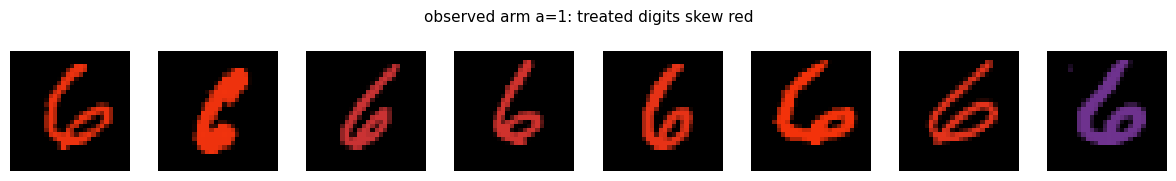

In [2]:
N_OBS, TARGET_A = 20000, 1
W_CONF, TAU = 10.0, 0.08

pools = load_digit_pools(root="../../data", device=device)
generator = torch.Generator(device=device).manual_seed(SEED)
X_obs, A_obs, Y_obs = sample_observed(pools, N_OBS, w_conf=W_CONF, tau=TAU,
                                      generator=generator)
data = to_model_range(Y_obs)
arm = A_obs == TARGET_A
print(f"n = {N_OBS}   arm a={TARGET_A} size = {int(arm.sum())}   "
      f"E[X | A={TARGET_A}] = {X_obs[arm].mean():.3f}   (marginal E[X] = 0.5)")

fig, axes = plt.subplots(1, 8, figsize=(12, 1.8))
for image, ax in zip(Y_obs[arm][:8], axes):
    ax.imshow(image.permute(1, 2, 0).cpu().numpy())
    ax.axis("off")
fig.suptitle(f"observed arm a={TARGET_A}: treated digits skew red", fontsize=11)
fig.tight_layout()
plt.show()

## 2. Autoencoder Feature Map

A convolutional autoencoder (latent dimension 32) trained on the observed images defines the latent
space of the flow: the encoder is the feature map of the kernel, and the decoder returns transported
particles to the image manifold.

reconstruction MSE: 0.0025


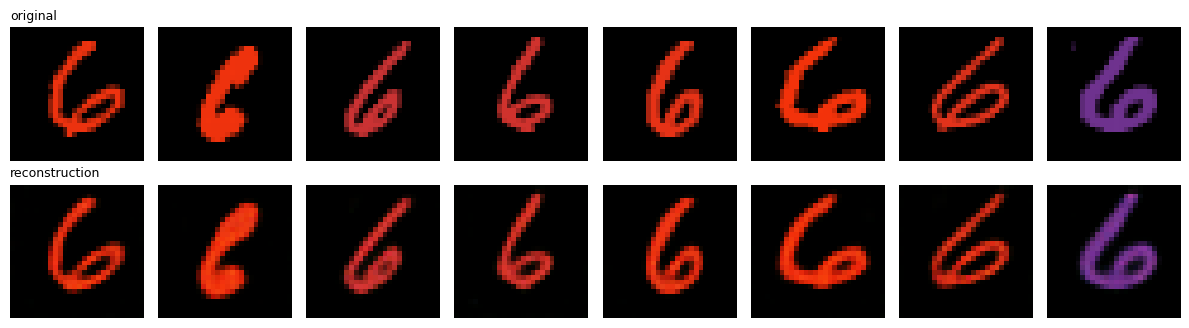

In [3]:
ae, history_ae = train_conv_ae(data, latent_dim=32, n_iterations=3000, batch_size=128,
                               learning_rate=1e-3, device=device,
                               generator=torch.Generator(device=device).manual_seed(SEED),
                               log_every=1500, verbose=False)
for parameter in ae.parameters():
    parameter.requires_grad_(False)
print(f"reconstruction MSE: {history_ae[-1][1]:.4f}")

with torch.no_grad():
    recon = ae(data[arm][:8])
fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for k in range(8):
    axes[0, k].imshow(Y_obs[arm][k].permute(1, 2, 0).cpu().numpy())
    axes[1, k].imshow(to_image_range(recon[k]).permute(1, 2, 0).cpu().numpy())
    for row in (0, 1):
        axes[row, k].axis("off")
axes[0, 0].set_title("original", fontsize=9, loc="left")
axes[1, 0].set_title("reconstruction", fontsize=9, loc="left")
fig.tight_layout()
plt.show()

## 3. Cross-Fitted DR Weight Fitting

The interventional embedding under $A = a^\*$ is a finite expansion over $n_{\mathrm{DR}}$ encoded
logged outcomes, $\hat\chi(a^\*) = \sum_i v_i\, k_Y(z_i, \cdot)$, with the cross-fitted one-step
doubly robust weights

$$
v_{\mathrm{DR}} = \tfrac1n (K + \lambda I)^{-1} (K_X \circ K_A^{a^\*}) \mathbf 1
\; + \; \tfrac1n \big[\hat w - (K + \lambda I)^{-1} K \hat w\big],
\qquad
\hat w_i = \frac{\mathbf 1\{a_i = a^\*\}}{\hat e_{a^\*}(x_i)} .
$$

All nuisances share one 5-fold split: the plug-in logistic propensity
(`dens_ratio_utils.LogisticPropensityModel`, well specified since the true propensity is logistic in
$x$), the conditional mean embedding behind both terms, and the per-fold ridge $\lambda_k$. The
kernel on the binary treatment is the delta kernel; the kernel on the confounder is a
median-heuristic RBF. The support is an $n_{\mathrm{DR}} = 4000$ subsample of the logged data, since
the conditional-mean-embedding solves are cubic in the support size.

In [4]:
N_DR = 4000
subsample = torch.randperm(N_OBS, generator=torch.Generator(device=device).manual_seed(SEED + 5),
                           device=device)[:N_DR]
X_s, A_s = X_obs[subsample], A_obs[subsample]
Z_s = encode_in_batches(ae.encode, data[subsample])

fold_ids = make_crossfit_fold_ids(N_DR, n_folds=5, seed=0)
torch.manual_seed(SEED)
e1 = crossfit_propensity(X_s.unsqueeze(1).double().cpu(), A_s.double().cpu(), fold_ids)
e_target = e1 if TARGET_A == 1 else 1.0 - e1
w_hat = (A_s.cpu() == TARGET_A).double() / e_target
on_arm = w_hat[A_s.cpu() == TARGET_A]
print(f"on-arm ESS = {(on_arm.sum() ** 2 / (on_arm ** 2).sum()).item():.0f} "
      f"of {len(on_arm)}   max weight = {w_hat.max():.1f}")

kernel_x = RBF(use_length_scale_heuristic=True)
K_x = kernel_x(X_s.unsqueeze(1).double().cpu())
K_a = (A_s[:, None] == A_s[None, :]).double().cpu()
K_a_target = (A_s == TARGET_A).double().cpu()[:, None].expand(N_DR, N_DR).contiguous()

K_pair = K_x * K_a
fold_lambdas = {}
for fold in np.unique(fold_ids):
    train = np.where(fold_ids != fold)[0]
    fold_lambdas[int(fold)], _ = select_regularization(K_pair[train][:, train],
                                                       Z_s[train, 0].double().cpu(), seed=0)
print(f"per-fold lambdas: {fold_lambdas}")

v_dr = cpme_dr_weights_crossfit(K_x, K_a, K_a_target, w_hat, fold_ids,
                                fold_lambdas).float().to(device)
print(f"DR weights:  sum(v) = {v_dr.sum():.3f}   sum|v| = {v_dr.abs().sum():.3f}")

on-arm ESS = 277 of 1941   max weight = 113.9


per-fold lambdas: {0: 10.0, 1: 10.0, 2: 10.0, 3: 0.0001, 4: 10.0}


DR weights:  sum(v) = 1.000   sum|v| = 1.000


## 4. The Pullback Kernel and the Two Constrained Parametrisations

Three samplers are compared, identical except for how (or whether) the particles are kept in
the image domain.

**Unconstrained.** $y \leftarrow y - \gamma\,\nabla_y f$, exactly the companions' Euler step
with the pullback kernel substituted.

**Projected (clamp).** The same step followed by $y \leftarrow \mathrm{clip}(y, -1, 1)$:
projected gradient descent onto the (convex) valid-image box.

**Reparametrised (tanh).** Flow a free variable $w$ with $y = \tanh(w)$, which lies in
$(-1, 1)$ for any $w$ — the decoder's own constraint, without the decoder. It is implemented
by pulling back through the composite encoder $E \circ \tanh$, so no new flow code is
needed; the chain rule then supplies the factor $1 - \tanh^2(w)$, which decelerates motion
smoothly near the boundary instead of stopping it dead as clipping does.

One subtlety this parametrisation forces: *every* argument of the composite kernel is passed
through $\tanh$, the target support included. The target must therefore be supplied in
$w$-space as $\mathrm{atanh}(y_i)$, or the flow is pulled toward images compressed into
$[-0.76, 0.76]$. The clip at $0.999$ is required because $85\%$ of ColorMNIST pixels sit at
exactly $-1$, where $\mathrm{atanh}$ diverges; the resulting round-trip error is printed
below and is negligible.

In [5]:
M = 1600
Z_arm = encode_in_batches(ae.encode, data[arm])
pick = torch.randperm(Z_arm.shape[0], generator=torch.Generator(device=device).manual_seed(SEED + 1),
                      device=device)[:M]
initial_images = data[arm][pick]

c_imq = imq_c_from_median(Z_s)
base_step = 0.15 * c_imq ** 2
flatten = lambda images: images.reshape(images.shape[0], -1)
initial_rows = flatten(initial_images).clone()
target_rows = flatten(data[subsample])

pullback = EncoderPullbackKernel(IMQKernel(c=c_imq, beta=-0.5), ae.encode,
                                 image_shape=(3, 28, 28))
pullback_tanh = EncoderPullbackKernel(IMQKernel(c=c_imq, beta=-0.5),
                                      lambda images: ae.encode(torch.tanh(images)),
                                      image_shape=(3, 28, 28))
ATANH_CLIP = 0.999
target_w = torch.atanh(target_rows.clamp(-ATANH_CLIP, ATANH_CLIP))
initial_w = torch.atanh(initial_rows.clamp(-ATANH_CLIP, ATANH_CLIP))
print(f"IMQ c = {c_imq:.2f}   base step 0.15c^2 = {base_step:.1f}")
print(f"atanh round-trip error: mean |tanh(atanh(y)) - y| = "
      f"{float((torch.tanh(target_w) - target_rows).abs().mean()):.6f}")


def pixel_flow(kernel, initial, targets, step, n_iterations=3000, project=False):
    "Euler flow on image-space (or w-space) particles, optionally projected to [-1, 1]."
    particles = initial.clone()
    for _ in range(n_iterations):
        gradient = witness_gradient(kernel, particles, targets, particles,
                                    target_weights=v_dr)
        particles = particles - step * gradient
        if project:
            particles = particles.clamp(-1.0, 1.0)
    objective = float(embedding_squared_distance(kernel, particles, targets, v_dr))
    return particles, objective


@torch.no_grad()
def ae_gap(images):
    "Mean ||AE(y) - y||: how far a batch sits from the autoencoder's image manifold."
    return float((ae(images.clamp(-1, 1)) - images).reshape(len(images), -1)
                 .norm(dim=1).mean())

IMQ c = 13.27   base step 0.15c^2 = 26.4
atanh round-trip error: mean |tanh(atanh(y)) - y| = 0.000847


## 5. What the Constraint Is Worth

Each sampler is run for $3000$ iterations at the companions' step, and the $\tanh$ flow is
then swept over two further orders of magnitude to check that its behaviour has settled.
Reported per run: the shared objective, the colour ratio (the intervention's target
statistic — the companion latent flow reaches $0.503$ against an oracle $0.497$), pixel
SW2, the raw pixel range, and the autoencoder gap.

In [6]:
_, Y_oracle = sample_interventional(pools, M, a=TARGET_A, tau=TAU,
                                    generator=torch.Generator(device=device).manual_seed(SEED + 9))
results = {}


def evaluate(name, images, objective):
    images_01 = to_image_range(images.reshape(M, 3, 28, 28))
    results[name] = dict(
        objective=objective,
        colour=float(color_ratio(images_01).mean()),
        sw2=sliced_wasserstein(flatten(images_01), flatten(Y_oracle), p=2, seed=0).item(),
        low=float(images.min()), high=float(images.max()),
        gap=ae_gap(images.reshape(M, 3, 28, 28)))
    r = results[name]
    print(f"{name:26s} {r['objective']:10.2e} {r['colour']:8.3f} {r['sw2']:8.4f} "
          f"[{r['low']:6.2f},{r['high']:5.2f}] {r['gap']:8.2f}")


print(f"{'sampler':26s} {'objective':>10s} {'colour':>8s} {'SW2':>8s} "
      f"{'pixel range':>14s} {'AE gap':>8s}")
rows, objective = pixel_flow(pullback, initial_rows, target_rows, base_step)
evaluate("unconstrained", rows, objective)
rows, objective = pixel_flow(pullback, initial_rows, target_rows, base_step, project=True)
evaluate("projected (clamp)", rows, objective)
w_rows, objective = pixel_flow(pullback_tanh, initial_w, target_w, base_step * 10)
tanh_images = torch.tanh(w_rows).reshape(M, 3, 28, 28)
evaluate("tanh, x10 (main)", torch.tanh(w_rows), objective)

for multiplier in (0.3, 1.0, 3.0, 30.0):
    w_sweep, objective = pixel_flow(pullback_tanh, initial_w, target_w,
                                    base_step * multiplier)
    evaluate(f"tanh, x{multiplier:g}", torch.tanh(w_sweep), objective)

print(f"\n{'initial (no flow)':26s} {'-':>10s} "
      f"{float(color_ratio(to_image_range(initial_images)).mean()):8.3f} "
      f"{sliced_wasserstein(flatten(to_image_range(initial_images)), flatten(Y_oracle), p=2, seed=0).item():8.4f} "
      f"[{-1.0:6.2f},{1.0:5.2f}] {ae_gap(initial_images):8.2f}")
print(f"{'latent companion':26s} {9.6e-06:10.2e} {0.503:8.3f} {0.0137:8.4f} "
      f"{'    (n/a)':>14s} {1.10:8.2f}")

sampler                     objective   colour      SW2    pixel range   AE gap


unconstrained                5.94e-06    0.677   0.0425 [ -1.70, 1.04]     5.02


projected (clamp)            6.77e-06    0.654   0.0418 [ -1.00, 1.00]     6.18


tanh, x10 (main)             4.99e-06    0.578   0.0255 [ -1.00, 1.00]     5.02


tanh, x0.3                   3.33e-04    0.647   0.0344 [ -1.00, 1.00]     3.59


tanh, x1                     3.46e-05    0.594   0.0273 [ -1.00, 1.00]     4.55


tanh, x3                     1.22e-05    0.582   0.0259 [ -1.00, 1.00]     4.83


tanh, x30                    2.40e-06    0.576   0.0253 [ -1.00, 1.00]     5.21

initial (no flow)                   -    0.728   0.0504 [ -1.00, 1.00]     2.86
latent companion             9.60e-06    0.503   0.0137          (n/a)     1.10


### The constraint fixes the range; it does not close the gap

The $\tanh$ sweep settles: a hundredfold increase in step moves the colour by about $0.02$
and leaves SW2 flat, while the objective keeps falling. The flow converges — to a point that
matches the target embedding better than the latent companion does, while remaining well
short of it on every statistic that describes the images.

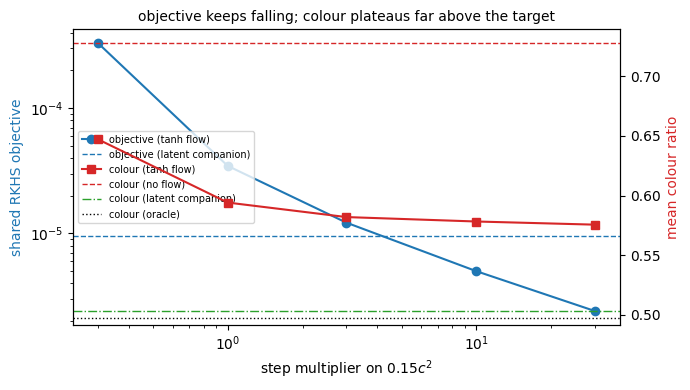

In [7]:
sweep_names = [f"tanh, x{m:g}" for m in (0.3, 1.0, 3.0, 10.0, 30.0)]
sweep_names = [n if n != "tanh, x10" else "tanh, x10 (main)" for n in sweep_names]
multipliers = [0.3, 1.0, 3.0, 10.0, 30.0]
fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.loglog(multipliers, [results[n]["objective"] for n in sweep_names], "o-",
           color="tab:blue", label="objective (tanh flow)")
ax1.axhline(9.6e-06, ls="--", color="tab:blue", lw=1, label="objective (latent companion)")
ax1.set_xlabel("step multiplier on $0.15c^2$")
ax1.set_ylabel("shared RKHS objective", color="tab:blue")
ax2 = ax1.twinx()
ax2.semilogx(multipliers, [results[n]["colour"] for n in sweep_names], "s-",
             color="tab:red", label="colour (tanh flow)")
ax2.axhline(float(color_ratio(to_image_range(initial_images)).mean()), ls="--",
            color="tab:red", lw=1, label="colour (no flow)")
ax2.axhline(0.503, ls="-.", color="tab:green", lw=1, label="colour (latent companion)")
ax2.axhline(0.497, ls=":", color="k", lw=1, label="colour (oracle)")
ax2.set_ylabel("mean colour ratio", color="tab:red")
lines = ax1.get_lines() + ax2.get_lines()
ax1.legend(lines, [line.get_label() for line in lines], fontsize=7, loc="center left")
ax1.set_title("objective keeps falling; colour plateaus far above the target", fontsize=10)
fig.tight_layout()
plt.show()

## 6. What the Images Look Like

Rows: the initial particles; the constrained ($\tanh$) flow's output; its perturbation,
amplified $3\times$; and an oracle draw. Genuine recolouring would concentrate on the
digit's foreground; encoder-fooling appears as diffuse structured patterns across the whole
frame, including the background.

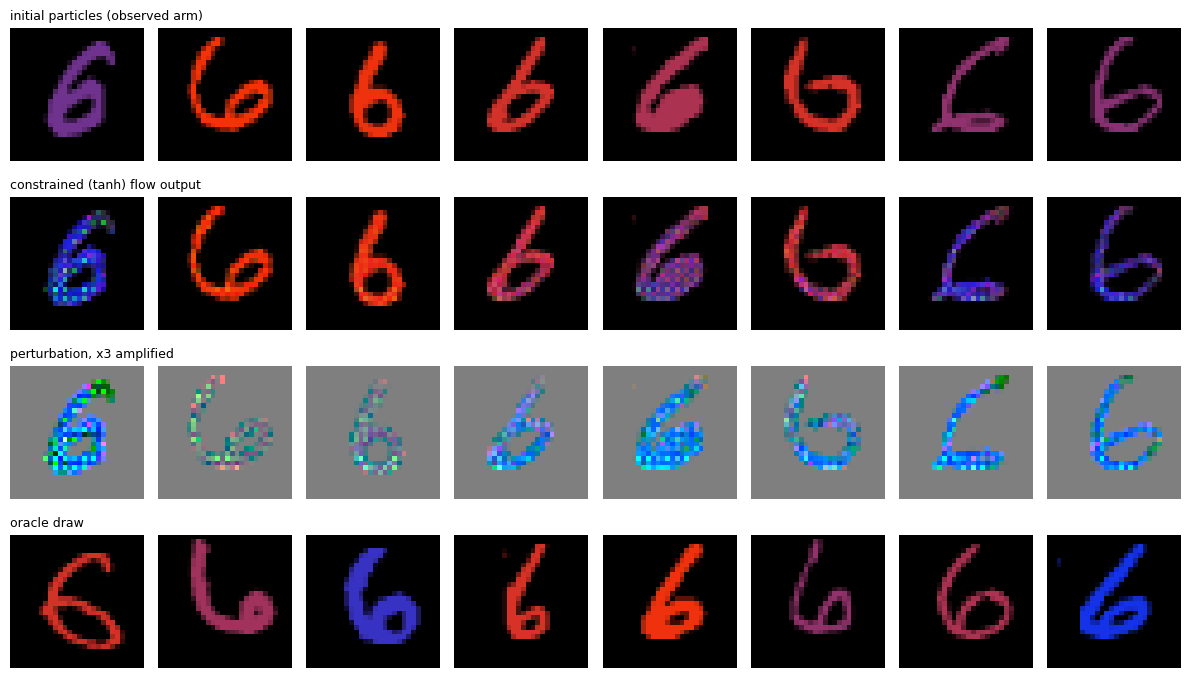

In [8]:
rows_to_show = [("initial particles (observed arm)", to_image_range(initial_images)),
                ("constrained (tanh) flow output", to_image_range(tanh_images)),
                ("perturbation, x3 amplified",
                 to_image_range(3.0 * (tanh_images - initial_images))),
                ("oracle draw", Y_oracle)]
fig, axes = plt.subplots(len(rows_to_show), 8, figsize=(12, 1.75 * len(rows_to_show)))
for row, (label, images) in enumerate(rows_to_show):
    for column in range(8):
        axes[row, column].imshow(images[column].permute(1, 2, 0).cpu().clamp(0, 1).numpy())
        axes[row, column].axis("off")
    axes[row, 0].set_title(label, fontsize=9, loc="left")
fig.tight_layout()
plt.show()

## 7. Metric Evaluation

The standard table against an oracle draw for the constrained flow, with the objective and
autoencoder gap alongside. The latent companion's row is quoted from its own notebook (same
data, target, kernel and step).

In [9]:
_, Y_oracle_2 = sample_interventional(pools, M, a=TARGET_A, tau=TAU,
                                      generator=torch.Generator(device=device).manual_seed(SEED + 10))
kernel_pixel = RBF(use_length_scale_heuristic=True)
_ = kernel_pixel(flatten(Y_oracle))

table = {"initial (observed arm)": (to_image_range(initial_images), None,
                                    ae_gap(initial_images)),
         "pixel flow (tanh pullback)": (to_image_range(tanh_images),
                                        results["tanh, x10 (main)"]["objective"],
                                        ae_gap(tanh_images)),
         "oracle floor": (Y_oracle_2, None, ae_gap(2.0 * Y_oracle_2 - 1.0))}
print(f"{'sample':28s} {'colour mean(std)':>17s} {'SW1':>8s} {'SW2':>8s} "
      f"{'MMD^2':>10s} {'objective':>11s} {'AE gap':>7s}")
for name, (images, objective, gap) in table.items():
    ratio = color_ratio(images).cpu().numpy()
    sw1 = sliced_wasserstein(flatten(images), flatten(Y_oracle), p=1, seed=0).item()
    sw2 = sliced_wasserstein(flatten(images), flatten(Y_oracle), p=2, seed=0).item()
    mmd2 = squared_mmd(kernel_pixel, flatten(images), flatten(Y_oracle),
                       unbiased=True).item()
    obj = f"{objective:11.2e}" if objective is not None else f"{'-':>11s}"
    print(f"{name:28s} {ratio.mean():10.3f}({ratio.std():.3f}) {sw1:8.4f} {sw2:8.4f} "
          f"{mmd2:10.2e} {obj} {gap:7.2f}")
print(f"{'latent companion (quoted)':28s} {0.503:10.3f}({0.279:.3f}) {0.0094:8.4f} "
      f"{0.0137:8.4f} {1.97e-03:10.2e} {9.60e-06:11.2e} {1.10:7.2f}")

sample                        colour mean(std)      SW1      SW2      MMD^2   objective  AE gap
initial (observed arm)            0.728(0.186)   0.0387   0.0504   4.11e-02           -    2.86
pixel flow (tanh pullback)        0.578(0.254)   0.0194   0.0255   1.03e-02    4.99e-06    5.02
oracle floor                      0.494(0.286)   0.0055   0.0081  -1.07e-04           -    3.12
latent companion (quoted)         0.503(0.279)   0.0094   0.0137   1.97e-03    9.60e-06    1.10


## Summary

The estimation half of this notebook is identical to its latent companion — the outcome
kernel enters only the sampler, so the same cross-fitted DR weights $v$ ($\sum v = 1$,
$\sum|v| = 1$, on-arm ESS $277/1941$) are reused verbatim. The only change is where the
particles live.

**The decoder was silently enforcing the image domain.** The unconstrained pixel flow drives
pixels to $[-1.70,\, 1.04]$ — outside the valid range, which is not a tuning artefact but the
absence of the $\tanh$ that terminates the decoder. Two restorations were measured. Clipping
onto the box after each step barely helps (colour $0.654$, SW2 $0.0418$, against
$0.677 / 0.0425$ unconstrained): pixels reaching the boundary stop dead there, and the
autoencoder gap actually *worsens* to $6.18$. Reparametrising as $y = \tanh(w)$ — the
decoder's own constraint, without the decoder — is much better, roughly doubling the
improvement over the initial sample: colour $0.728 \to 0.578$ and SW2 $0.0504 \to 0.0255$,
with SW1 halved ($0.0387 \to 0.0194$) and the colour spread opening from $0.186$ to $0.254$
against the oracle's $0.286$. The factor $1 - \tanh^2(w)$ decelerates particles smoothly
near the boundary rather than truncating them, which is evidently what matters.

**The constraint does not close the gap.** Sweeping the $\tanh$ step over two orders of
magnitude, the objective falls monotonically ($3.3\text{e-}04 \to 2.4\text{e-}06$) while the
image statistics plateau: colour $0.647 \to 0.576$, SW2 $0.0344 \to 0.0253$, essentially flat
past $\times 3$. So the flow *converges*, in range, to a point where it matches the target
embedding **better than the latent companion does** — objective $4.99\text{e-}06$ versus
$9.60\text{e-}06$ — while being $1.9\times$ worse in pixel SW2 ($0.0255$ vs $0.0137$) and
still $0.08$ short on colour ($0.578$ vs $0.503$, oracle $0.494$). The autoencoder gap is the
tell: $5.02$ both with and without the constraint, against $2.86$ for the observed images,
$3.12$ for an oracle draw, and $1.10$ for the decoder-native latent flow. The constraint
fixes the *range*; it does nothing about the *manifold*. The amplified perturbation grid
shows why — diffuse structured texture spread over foreground and background alike, rather
than recolouring concentrated on the digit.

**The conclusion is therefore stronger than before the constraint was imposed.** Matching the
mean embedding of a non-robust encoder is not sufficient for sampling, and this cannot be
dismissed as divergence or as an invalid-image artefact: the flow stays in $[-1, 1]$ by
construction, converges, and beats the working sampler on the shared objective while
producing visibly worse samples. The latent flow works because the **decoder projects every
move onto the image manifold**, not because of the objective it optimises. Evaluate against
held-out outcome-space samples; never read the optimised objective as evidence of sample
quality.

**Two practical notes.** (i) In the $\tanh$ parametrisation every argument of the composite
kernel passes through $\tanh$, the *target support included* — the target must be supplied in
$w$-space as $\mathrm{atanh}(y_i)$, or the flow is pulled toward images compressed into
$[-0.76, 0.76]$. The clip at $0.999$ (needed because $85\%$ of ColorMNIST pixels sit exactly
at $-1$) costs a round-trip error of $0.000847$. (ii) The base kernel matters for behaviour
but not for the diagnosis: swapping IMQ for the scale-free Riesz kernel makes this flow
*diverge* at every step tried, pixels reaching $\pm 900$ with SW2 worsening as the step
grows. IMQ is kept here precisely because it converges, isolating encoder-fooling from
blow-up. Both failures share one cause — no decoder projection.